# 1. Preprocessing

In [125]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold, cross_val_predict, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, RocCurveDisplay, roc_curve, roc_auc_score, PrecisionRecallDisplay, average_precision_score, precision_score, recall_score, f1_score
from pathlib import Path

In [126]:
# Reading the Dataset
root = Path.cwd().parent
df = pd.read_csv(root / "data/processed/telco_churn_cleaned.csv")
df.head(5)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [127]:
numeric_cols = ["tenure", "MonthlyCharges"]
categorical_cols = [
    "gender", "Partner", "Dependents", "PhoneService", "MultipleLines",
    "InternetService", "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies", "Contract",
    "PaperlessBilling", "PaymentMethod", "SeniorCitizen"
]

numeric_pipeline = Pipeline([
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_cols),
    ("cat", categorical_pipeline, categorical_cols)
])

# 2. Train - Test Split

In [128]:
X = df.drop(columns=["customerID", "Churn", "TotalCharges"])
y = df["Churn"].map({"Yes": 1, "No": 0})

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Train churn rate: {y_train.mean():.3f}, Test churn rate: {y_test.mean():.3f}")

Train: (5625, 18), Test: (1407, 18)
Train churn rate: 0.266, Test churn rate: 0.266


# 3. Baseline Model

An untuned Logistic Regression model is used as the baseline to assess its initial performance in predicting customer churn.

The results will serve as a benchmark for evaluating whether cross-validation, hyperparameter tuning, and more complex models lead to improvements in predictive performance.

In [129]:
baseline_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=10000))
])

baseline_pipeline.fit(X_train, y_train)
baseline_pred = baseline_pipeline.predict(X_test)

print("=== Baseline Logitic Regression ===")
print(classification_report(y_test, baseline_pred))

=== Baseline Logitic Regression ===
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1033
           1       0.65      0.57      0.61       374

    accuracy                           0.80      1407
   macro avg       0.75      0.73      0.74      1407
weighted avg       0.80      0.80      0.80      1407



The baseline Logistic Regression model achieved an overall accuracy of 80%.

However, the model performed better at identifying customers who stayed (89% recall) than customers who churned (57% recall). This may be partly due to class imbalance, as approximately 73% of customers did not churn.

From a business perspective, this means the model failed to identify approximately 43% of customers who actually churned, resulting in missed opportunities for customer retention.

Therefore, the next step is to improve the model's ability to identify churners while minimising unnecessary retention efforts.

## 3.1. Baseline Confusion Matrix

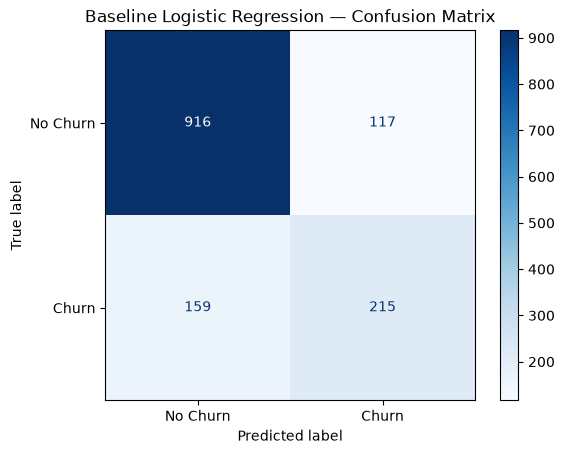

In [130]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    baseline_pred,
    display_labels=["No Churn", "Churn"],
    cmap="Blues",
    values_format="d"
)

plt.title("Baseline Logistic Regression — Confusion Matrix")
plt.show()

The baseline model correctly identified 916 non-churning customers and 215 churning customers.

However, it failed to identify 159 customers who actually churned, representing approximately 43% of all churners in the test set.

From a business perspective, these false negatives represent missed opportunities for customer retention. This suggests that improving churn recall should be a priority in subsequent model development.

## 3.2. Baseline Model - Overfitting and Underfitting Assessment

In [131]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_validate(
    baseline_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc",
    return_train_score=True
)

print("Training ROC-AUC:", scores["train_score"].mean())
print("Validation ROC-AUC:", scores["test_score"].mean())

Training ROC-AUC: 0.8490724985221118
Validation ROC-AUC: 0.8446476147286759


The Logistic Regression model achieved a mean training ROC-AUC of 0.849 and a mean validation ROC-AUC of 0.845 using 5-fold stratified cross-validation.

The small difference between the two scores (0.004) suggests that the model generalises well, with no strong indication of overfitting.

These results establish a reliable performance benchmark for subsequent hyperparameter tuning and model comparisons.

## 3.3. Baseline Model - Precision-Recall Curve

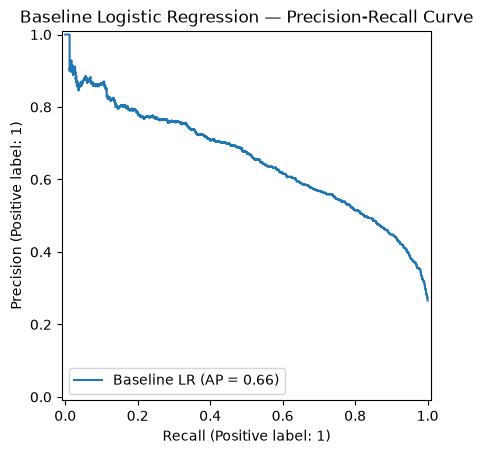

In [132]:
baseline_prob_cv = cross_val_predict(
    baseline_pipeline,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba"
)[:, 1]

# Average precision
ap = average_precision_score(y_train, baseline_prob_cv)

# Plot
PrecisionRecallDisplay.from_predictions(
    y_train,
    baseline_prob_cv,
    name="Baseline LR"
)

plt.title("Baseline Logistic Regression — Precision-Recall Curve")
plt.show()

The baseline Logistic Regression model achieved an Average Precision (AP) score of 0.656, indicating that it can distinguish customers at risk of churn substantially better than random ranking.

The curve shows that precision generally decreases as recall increases. This means identifying more customers who actually churn also increases the number of non-churning customers incorrectly flagged as at risk.

From a business perspective, the classification threshold should balance the benefits of identifying additional churners against the costs of unnecessary retention efforts.

## 3.3. Baseline Model - Overall Findings

The baseline Logistic Regression model achieved an accuracy of 80%, with a churn precision of 65% and recall of 57%.

While the model performs reasonably well overall, it struggles to identify customers who actually churn, missing approximately 43% of them. This may be partly explained by the class imbalance in the dataset.

However, the cross-validation results show similar training (0.849) and validation (0.845) ROC-AUC scores, suggesting good generalisation with no strong evidence of overfitting.

Overall, the baseline provides a reasonable starting point, but there is room to improve churn detection. The next step is to investigate class weighting and hyperparameter tuning to determine whether recall can be improved without introducing too many false positives.

# 4. Class Imbalance Handling

In [133]:
baseline_imbalance_handling_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(class_weight="balanced", max_iter=10000))
])

baseline_imbalance_handling_pipeline.fit(X_train, y_train)
baseline_imbalance_handling_pred = baseline_imbalance_handling_pipeline.predict(X_test)

print("=== Baseline Imbalance Handling Logitic Regression ===")
print(classification_report(y_test, baseline_imbalance_handling_pred))

=== Baseline Imbalance Handling Logitic Regression ===
              precision    recall  f1-score   support

           0       0.90      0.71      0.79      1033
           1       0.49      0.78      0.60       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.79      0.73      0.74      1407



After applying `class_weight="balanced"`, the model's churn recall increased from 57% to 78%, indicating that it successfully identifies a greater proportion of customers who actually churn.

However, churn precision decreased from 65% to 49%, meaning that more customers predicted to churn were actually non-churners.

Overall accuracy also declined from 80% to 73%, while the churn F1-score remained relatively unchanged (0.61 to 0.60).

These results show that class weighting improves the model's ability to detect churners but introduces more false positives.

From a business perspective, this creates a trade-off between identifying more at-risk customers and avoiding unnecessary retention costs.

## 4.1. Class Imbalance Handling - Confusion Matrix

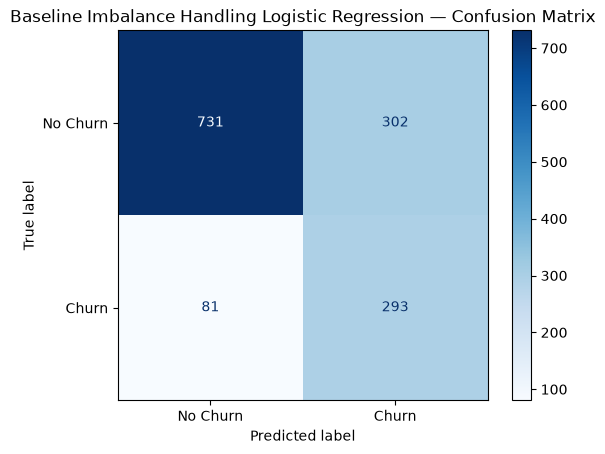

In [134]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    baseline_imbalance_handling_pred,
    display_labels=["No Churn", "Churn"],
    cmap="Blues",
    values_format="d"
)

plt.title("Baseline Imbalance Handling Logistic Regression — Confusion Matrix")
plt.show()

The confusion matrix shows that applying balanced class weights reduced false negatives from 159 to 81, allowing the model to correctly identify 293 churners compared with 215 in the original baseline.

However, false positives increased from 117 to 302, meaning more customers who would have stayed were incorrectly classified as churners.

From a business perspective, the balanced model reduces missed retention opportunities but may lead to higher costs from unnecessary retention efforts.

This highlights the trade-off between identifying more churners and incorrectly targeting customers who are unlikely to leave.

## 4.2. Class Imbalance Handling - Overfitting and Underfitting Assessment

In [135]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scores = cross_validate(
    baseline_imbalance_handling_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc",
    return_train_score=True
)

print("Training ROC-AUC:", scores["train_score"].mean())
print("Validation ROC-AUC:", scores["test_score"].mean())

Training ROC-AUC: 0.848953103363107
Validation ROC-AUC: 0.844411152590961


The Imbalanced Logistic Regression model achieved a mean training ROC-AUC of 0.849 and a mean validation ROC-AUC of 0.844 using 5-fold stratified cross-validation.

The small difference between the two scores (0.005) suggests that the model generalises well, with no strong indication of overfitting.

Interestingly, ROC-AUC remained nearly identical to the original baseline, despite the improvement in churn recall. This suggests that class weighting changed the model's classification behaviour without significantly improving its overall ability to distinguish churners from non-churners.

These findings provide a useful benchmark for subsequent hyperparameter tuning and model comparison.

## 4.3. Class Imbalance Handling - Precision and Recall Curve

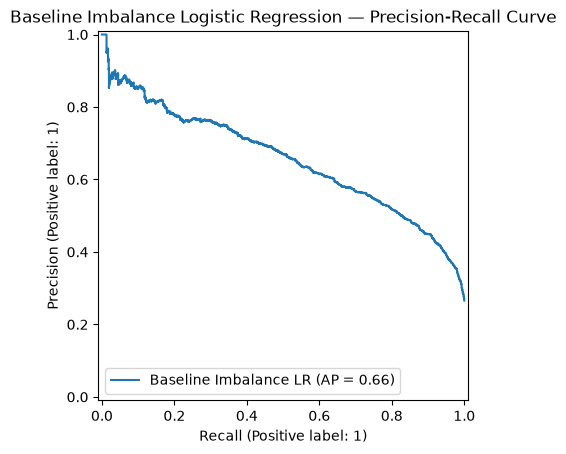

In [136]:
baseline_imbalance_handling_prob_cv = cross_val_predict(
    baseline_imbalance_handling_pipeline,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba"
)[:, 1]

# Average precision
ap = average_precision_score(y_train, baseline_imbalance_handling_prob_cv)

# Plot
PrecisionRecallDisplay.from_predictions(
    y_train,
    baseline_imbalance_handling_prob_cv,
    name="Baseline Imbalance LR"
)

plt.title("Baseline Imbalance Logistic Regression — Precision-Recall Curve")
plt.show()

The balanced Logistic Regression model achieved an Average Precision score of approximately 0.66, nearly identical to the original baseline.

Despite the improvement in churn recall, the overall Precision–Recall performance remained largely unchanged. This suggests that class weighting primarily changed the model's classification behaviour rather than improving its ability to distinguish churners from non-churners.

From a business perspective, class weighting allows the model to identify more customers at risk of churn, but also increases the number of false positives.

Overall, class weighting improves churn detection at the default classification threshold, but does not provide a meaningful improvement in overall ranking performance.

## 4.4. Class Imbalance Handling  - Overall Findings

Applying balanced class weights improved churn recall from 57% to 78%, allowing the model to identify more customers who actually churned.

However, this improvement came at the cost of lower precision (65% to 49%) and accuracy (80% to 73%). The model produced more false positives, potentially increasing unnecessary retention costs.

Cross-validation results showed a validation ROC-AUC of 0.844, nearly identical to the original baseline. This suggests that class weighting improved churn detection at the default classification threshold without significantly improving the model's overall ability to distinguish churners from non-churners.

Overall, the balanced model offers better churn recall but sacrifices precision. Further hyperparameter tuning and model comparison are needed to determine which approach provides the best balance between identifying at-risk customers and minimising unnecessary retention efforts.

# 5. Training and Comparing Other Models

| Model | Core Idea | Sensitive to |
|---|---|---|
| Logistic Regression (L1/Lasso) | Uses L1 regularisation to shrink some coefficients to zero, effectively selecting features | Feature scaling and regularisation strength |
| Random Forest | Combines multiple decision trees to improve prediction stability and capture nonlinear patterns | Tree depth, number of trees, and class imbalance |
| Gradient Boosting | Builds decision trees sequentially, with each tree correcting errors from previous trees | Learning rate, tree depth, and number of trees |

In [137]:
models = {
    "LogReg_L1": LogisticRegression(penalty="l1", solver="liblinear", class_weight="balanced", max_iter=1000),
    "RandomForest": RandomForestClassifier(class_weight="balanced", random_state=42),
    "GradientBoosting": GradientBoostingClassifier(random_state=42)
}

In [138]:
def evaluate_model(model, X_train, y_train, model_name, cv):

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    # Generate out-of-fold predictions
    y_pred = cross_val_predict(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        method="predict"
    )

    # Classification report
    print(f"=== {model_name} ===")
    print(classification_report(y_train, y_pred))

    # Confusion matrix
    ConfusionMatrixDisplay.from_predictions(
        y_train,
        y_pred,
        display_labels=["No Churn", "Churn"],
        cmap="Blues",
        values_format="d"
    )

    plt.title(f"{model_name} — Confusion Matrix")
    plt.show()

    return y_pred

=== LogReg_L1 ===
              precision    recall  f1-score   support

           0       0.91      0.74      0.81      4130
           1       0.52      0.80      0.63      1495

    accuracy                           0.75      5625
   macro avg       0.71      0.77      0.72      5625
weighted avg       0.81      0.75      0.76      5625



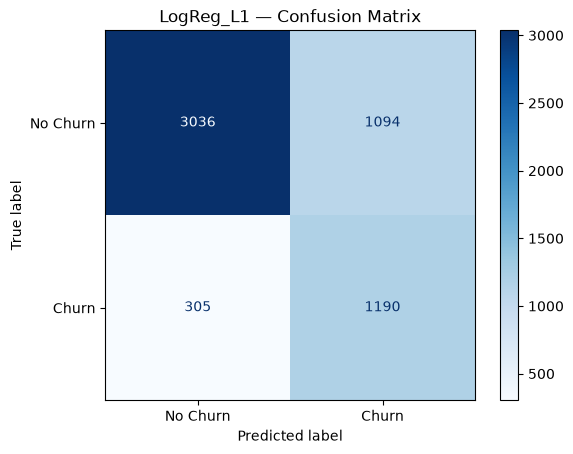

=== RandomForest ===
              precision    recall  f1-score   support

           0       0.86      0.82      0.84      4130
           1       0.56      0.63      0.59      1495

    accuracy                           0.77      5625
   macro avg       0.71      0.73      0.72      5625
weighted avg       0.78      0.77      0.77      5625



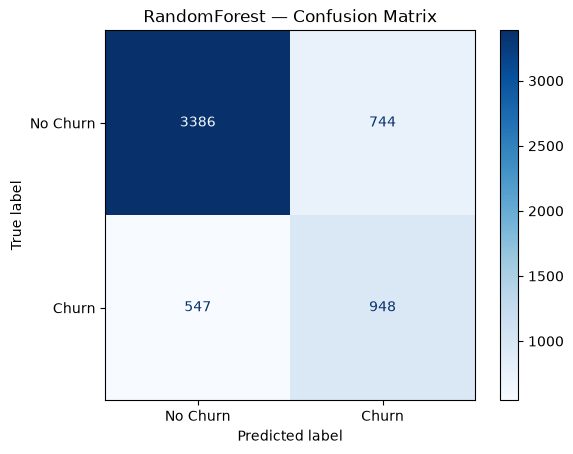

=== GradientBoosting ===
              precision    recall  f1-score   support

           0       0.84      0.90      0.87      4130
           1       0.66      0.52      0.58      1495

    accuracy                           0.80      5625
   macro avg       0.75      0.71      0.73      5625
weighted avg       0.79      0.80      0.79      5625



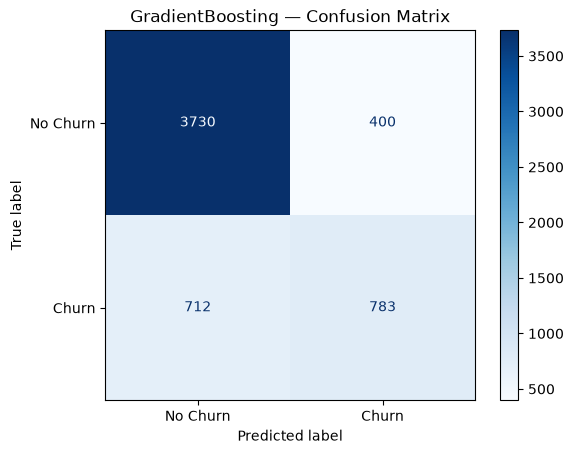

In [139]:
model_predictions = {}

for name, model in models.items():
    model_predictions[name] = evaluate_model(
        model,
        X_train,
        y_train,
        name,
        cv
    )

Three models were evaluated to determine which performs best at predicting customer churn.

Logistic Regression (L1) identified the most churners (80% recall), but also incorrectly flagged many customers who would have stayed, potentially increasing retention costs.

Random Forest identified 63% of churners, but showed signs of overfitting. This suggests that the model may be too complex and could benefit from further tuning.

Gradient Boosting achieved the highest accuracy (80%) and churn precision (66%), meaning fewer unnecessary retention efforts. However, it only identified 52% of actual churners.

Overall, Logistic Regression was the most effective at identifying customers at risk of leaving, while Gradient Boosting was more selective in its predictions.

In [140]:
def evaluate_cv(model, X_train, y_train, model_name):
    cv = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="roc_auc",
        return_train_score=True,
        n_jobs=-1
    )

    train_auc = scores["train_score"].mean()
    val_auc = scores["test_score"].mean()
    val_std = scores["test_score"].std()

    print(f"=== {model_name} ===")
    print(f"Training ROC-AUC:   {train_auc:.4f}")
    print(f"Validation ROC-AUC: {val_auc:.4f}")
    print(f"Validation Std:     {val_std:.4f}")
    print(f"Train-Val Gap:      {train_auc - val_auc:.4f}")
    print()

    return scores

In [141]:
cv_results = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    scores = evaluate_cv(
        pipeline,
        X_train,
        y_train,
        name
    )

    cv_results[name] = scores

=== LogReg_L1 ===
Training ROC-AUC:   0.8488
Validation ROC-AUC: 0.8444
Validation Std:     0.0059
Train-Val Gap:      0.0044

=== RandomForest ===
Training ROC-AUC:   1.0000
Validation ROC-AUC: 0.8151
Validation Std:     0.0074
Train-Val Gap:      0.1849

=== GradientBoosting ===
Training ROC-AUC:   0.8846
Validation ROC-AUC: 0.8467
Validation Std:     0.0025
Train-Val Gap:      0.0379



The three models were evaluated using 5-fold stratified cross-validation to compare their predictive performance and generalisation.

- Logistic Regression (L1) achieved a validation ROC-AUC of 0.8444, with a small training-validation gap, indicating good generalisation.

- Random Forest achieved a perfect training ROC-AUC of 1.0 but a lower validation score of 0.8151, suggesting substantial overfitting.

- Gradient Boosting achieved the highest validation ROC-AUC of 0.8467, although its larger training-validation gap suggests some overfitting.

Overall, Logistic Regression demonstrated the most consistent generalisation, while Gradient Boosting achieved slightly better validation performance.

These findings provide a basis for hyperparameter tuning, particularly to reduce overfitting in the tree-based models and assess whether further improvements are possible.

# 6. Hyperparameter Tuning

In [142]:
param_grids = {
    "LogReg_L1": {
        "classifier__C": [0.01, 0.1, 1, 10],
        "classifier__class_weight": [None, "balanced"]
    },

    "RandomForest": {
        "classifier__n_estimators": [100, 200],
        "classifier__max_depth": [5, 10, None],
        "classifier__min_samples_leaf": [1, 5, 10]
    },

    "GradientBoosting": {
        "classifier__n_estimators": [100, 200],
        "classifier__learning_rate": [0.05, 0.1],
        "classifier__max_depth": [2, 3]
    }
}

In [143]:
grid_results = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    grid = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        cv=cv,
        scoring={
            "roc_auc": "roc_auc",
            "average_precision": "average_precision",
            "recall": "recall"
        },
        refit="roc_auc",
        n_jobs=-1,
        return_train_score=True
    )

    grid.fit(X_train, y_train)

    grid_results[name] = grid

    print(f"\n=== {name} ===")
    print("Best Parameters:", grid.best_params_)
    print(f"Best CV ROC-AUC: {grid.best_score_:.4f}")


=== LogReg_L1 ===
Best Parameters: {'classifier__C': 0.1, 'classifier__class_weight': 'balanced'}
Best CV ROC-AUC: 0.8449

=== RandomForest ===
Best Parameters: {'classifier__max_depth': None, 'classifier__min_samples_leaf': 10, 'classifier__n_estimators': 200}
Best CV ROC-AUC: 0.8461

=== GradientBoosting ===
Best Parameters: {'classifier__learning_rate': 0.05, 'classifier__max_depth': 2, 'classifier__n_estimators': 200}
Best CV ROC-AUC: 0.8502


GridSearchCV improved the validation ROC-AUC scores of all three models.

Random Forest showed the largest improvement, increasing from 0.815 to 0.846, suggesting that adjusting its complexity helped improve performance on unseen validation data.

Logistic Regression showed minimal improvement, indicating that its original configuration was already performing well.

Gradient Boosting achieved the highest validation ROC-AUC of 0.850, making it the strongest-performing model based on this metric.

However, the differences between the tuned models are relatively small. Further evaluation of precision, recall, and overfitting is needed before selecting the final model.


=== Tuned LogReg_L1 ===
              precision    recall  f1-score   support

    No Churn       0.91      0.73      0.81      4130
       Churn       0.52      0.80      0.63      1495

    accuracy                           0.75      5625
   macro avg       0.71      0.77      0.72      5625
weighted avg       0.81      0.75      0.76      5625



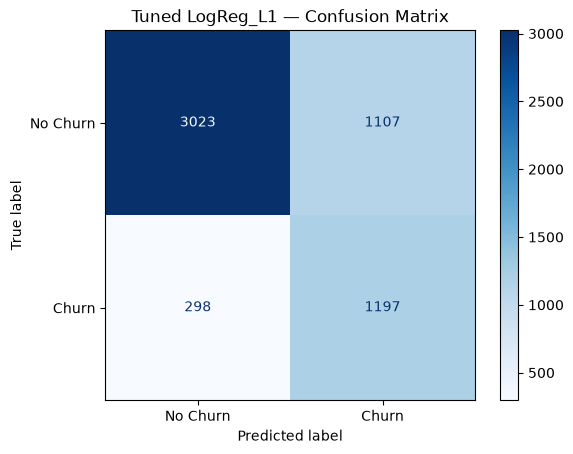


=== Tuned RandomForest ===
              precision    recall  f1-score   support

    No Churn       0.90      0.75      0.82      4130
       Churn       0.53      0.78      0.63      1495

    accuracy                           0.76      5625
   macro avg       0.72      0.76      0.72      5625
weighted avg       0.80      0.76      0.77      5625



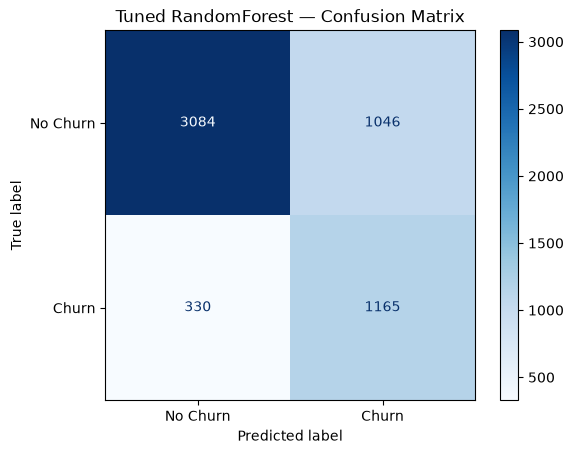


=== Tuned GradientBoosting ===
              precision    recall  f1-score   support

    No Churn       0.84      0.91      0.87      4130
       Churn       0.67      0.53      0.59      1495

    accuracy                           0.80      5625
   macro avg       0.76      0.72      0.73      5625
weighted avg       0.80      0.80      0.80      5625



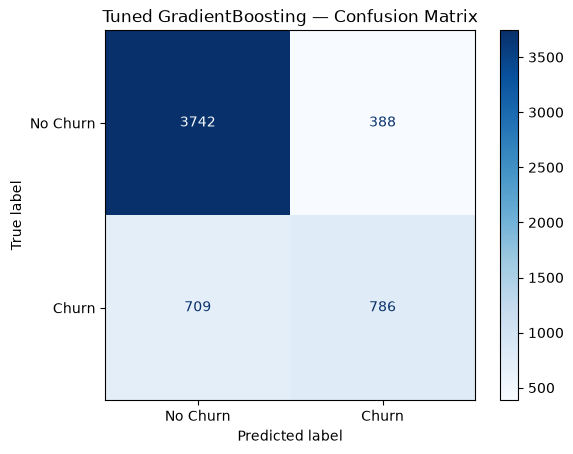

In [144]:
for name, grid in grid_results.items():

    # Retrieve best tuned model
    best_model = grid.best_estimator_

    # Generate cross-validation predictions
    y_pred = cross_val_predict(
        best_model,
        X_train,
        y_train,
        cv=cv,
        method="predict",
        n_jobs=-1
    )

    # Classification report
    print(f"\n=== Tuned {name} ===")
    print(classification_report(
        y_train,
        y_pred,
        target_names=["No Churn", "Churn"]
    ))

    # Confusion matrix
    ConfusionMatrixDisplay.from_predictions(
        y_train,
        y_pred,
        display_labels=["No Churn", "Churn"],
        cmap="Blues",
        values_format="d"
    )

    plt.title(f"Tuned {name} — Confusion Matrix")
    plt.show()

Hyperparameter tuning produced different results across the three models:

- Logistic Regression (L1) showed minimal improvement, maintaining a churn recall of 80% and a validation ROC-AUC of 0.845. It continued to identify the most churners but generated many false positives.

- Random Forest showed the largest improvement, with churn recall increasing from 63% to 78% and validation ROC-AUC rising from 0.815 to 0.846. However, this also resulted in more false positives.

- Gradient Boosting achieved the highest validation ROC-AUC (0.850) and churn precision (67%), but identified only 53% of actual churners.

Overall, Logistic Regression and Random Forest performed better at identifying customers at risk of leaving, while Gradient Boosting generated fewer unnecessary retention alerts.

Although Gradient Boosting achieved the highest ROC-AUC, the differences between the three models were relatively small.

The next step is to evaluate the tuned models for potential overfitting before selecting the most suitable model based on predictive performance and business priorities.

In [145]:
for name, grid in grid_results.items():
    evaluate_cv(
        grid.best_estimator_,
        X_train,
        y_train,
        f"Tuned {name}"
    )

=== Tuned LogReg_L1 ===
Training ROC-AUC:   0.8483
Validation ROC-AUC: 0.8449
Validation Std:     0.0058
Train-Val Gap:      0.0035

=== Tuned RandomForest ===
Training ROC-AUC:   0.8956
Validation ROC-AUC: 0.8461
Validation Std:     0.0057
Train-Val Gap:      0.0495

=== Tuned GradientBoosting ===
Training ROC-AUC:   0.8651
Validation ROC-AUC: 0.8502
Validation Std:     0.0039
Train-Val Gap:      0.0149



All three tuned models demonstrated reasonably good generalisation, achieving validation ROC-AUC scores between 0.845 and 0.850.

Logistic Regression showed the smallest training-validation gap (0.004), indicating little evidence of overfitting.

Random Forest showed substantial improvement, with its training-validation gap decreasing from 0.185 to 0.050. Although some overfitting remains, tuning significantly improved its generalisation.

Gradient Boosting also demonstrated good generalisation, achieving the highest validation ROC-AUC (0.850) with a relatively small gap (0.015).

Overall, hyperparameter tuning improved model stability and reduced overfitting, particularly for the tree-based models. None of the models showed clear evidence of severe underfitting, although this cannot be ruled out from these scores alone.

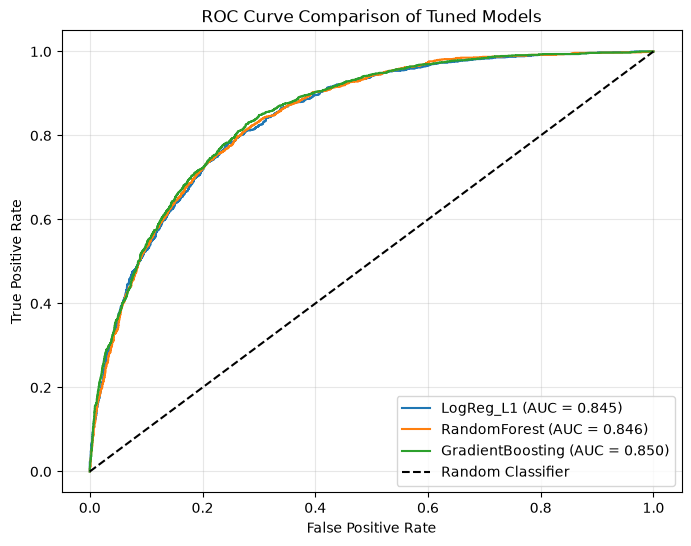

In [146]:
plt.figure(figsize=(8, 6))

for name, grid in grid_results.items():
    best_model = grid.best_estimator_
    
    y_prob = cross_val_predict(
        best_model,
        X_train,
        y_train,
        cv=cv,
        method="predict_proba",
        n_jobs=-1
    )[:, 1]
    
    fpr, tpr, _ = roc_curve(y_train, y_prob)
    auc_score = roc_auc_score(y_train, y_prob)
    
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_score:.3f})")

# Random classifier line
plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison of Tuned Models")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

The ROC-AUC comparison shows that all three models achieved similar predictive performance, with Gradient Boosting achieving a slightly higher AUC of 0.850.

However, the primary business objective is to identify customers at risk of leaving so that the company can take preventive retention measures. Since failing to identify actual churners (false negatives) may result in lost revenue, churn recall was prioritised during model selection.

Both Logistic Regression (L1) and Random Forest performed well in identifying churners, achieving recall scores of 80% and 78%, respectively. These results were substantially higher than Gradient Boosting's recall of 53% at the default classification threshold.

Although Random Forest achieved similar performance to Logistic Regression, Logistic Regression was selected because of its simplicity, interpretability, and consistent generalisation performance.

Furthermore, L1 regularisation enables feature selection by reducing certain coefficients to zero, allowing us to identify which customer characteristics contribute to the model's predictions. This provides additional value by helping the business understand the factors associated with customer churn.

Overall, Logistic Regression (L1) was selected as the preferred model because it offers a strong balance between churn detection, predictive performance, and interpretability.

However, the model's relatively low precision means that false positives remain a concern. Classification threshold adjustments and the costs of retention interventions should therefore be considered when determining how the model would be used in practice.

# 7. Lasso Feature Selection

In [147]:
# Retrieve the best tuned Logistic Regression
best_lr = grid_results["LogReg_L1"].best_estimator_

# Extract feature names after one-hot encoding
feature_names = best_lr.named_steps["preprocessor"].get_feature_names_out()

# Extract coefficients
coefficients = best_lr.named_steps["classifier"].coef_[0]

# Create a DataFrame
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

feature_importance["Abs_Coefficient"] = (
    feature_importance["Coefficient"].abs()
)

# Identify features retained by L1
selected_features = feature_importance[
    feature_importance["Abs_Coefficient"] > 1e-6
].sort_values("Abs_Coefficient", ascending=False)

print(f"Total encoded features: {len(feature_importance)}")
print(f"Selected features: {len(selected_features)}")
print(f"Zero coefficients: {len(feature_importance) - len(selected_features)}")

display(selected_features.head(15))

Total encoded features: 45
Selected features: 23
Zero coefficients: 22


,Feature,Coefficient,Abs_Coefficient
34,cat__Contract_Month-to-month,0.762297,0.762297
0,num__tenure,-0.761791,0.761791
1,num__MonthlyCharges,0.662237,0.662237
9,cat__PhoneService_Yes,-0.616992,0.616992
36,cat__Contract_Two year,-0.568074,0.568074
16,cat__OnlineSecurity_No,0.427609,0.427609
27,cat__TechSupport_Yes,-0.413413,0.413413
41,cat__PaymentMethod_Electronic check,0.329076,0.329076
13,cat__InternetService_DSL,-0.289965,0.289965
37,cat__PaperlessBilling_No,-0.243590,0.243590


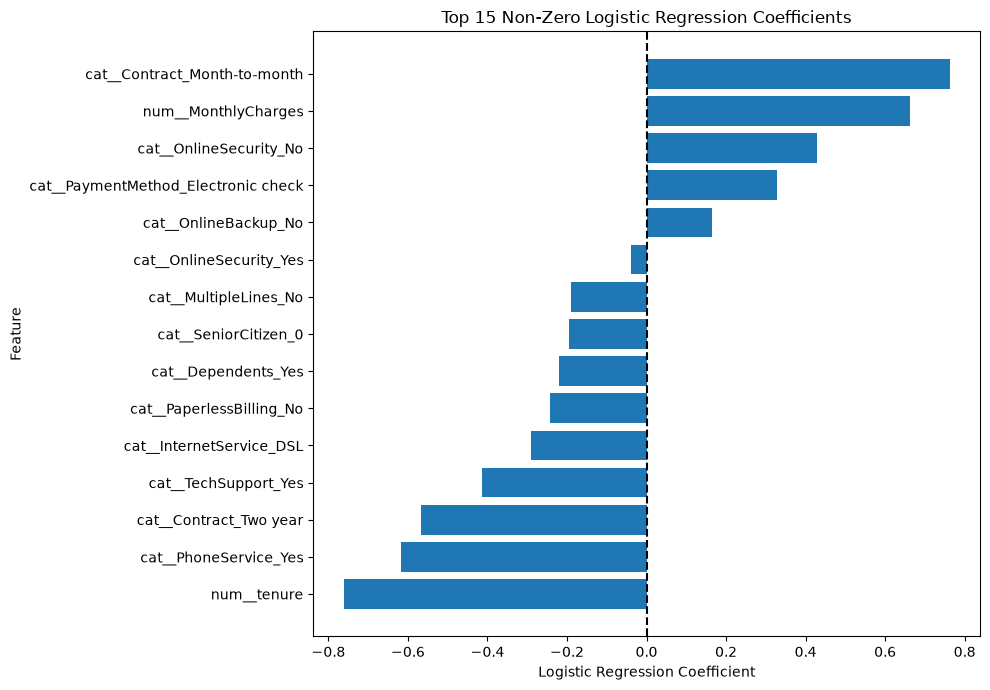

In [148]:
top_features = selected_features.head(15).sort_values("Coefficient")

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Coefficient"]
)

plt.axvline(0, color="black", linestyle="--")

plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Feature")
plt.title("Top 15 Non-Zero Logistic Regression Coefficients")

plt.tight_layout()
plt.show()

L1-regularised Logistic Regression was used to identify features associated with customer churn.

The results show that month-to-month contracts, higher monthly charges, and electronic check payments are among the strongest indicators associated with increased churn risk.

In contrast, longer customer tenure, two-year contracts, and access to services such as online security and technical support are associated with lower predicted churn risk.

From a business perspective, these findings suggest that customers with shorter subscription histories, flexible contracts, and higher monthly charges may warrant closer attention in retention efforts.

However, these relationships are predictive associations and do not necessarily indicate that the identified features directly cause customer churn.

# 8. Classification Threshold Analysis — Balancing Precision and Recall

By default, Logistic Regression uses a classification threshold of 0.5 to classify customers as churners or non-churners. However, changing this threshold affects the model's precision and recall.

Since the business objective is to identify customers at risk of churning, different thresholds were evaluated to understand the trade-off between identifying more potential churners and incorrectly flagging customers who would otherwise stay.

In [149]:
best_lr = grid_results["LogReg_L1"].best_estimator_

y_prob_cv = cross_val_predict(
    best_lr,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

thresholds = [0.3, 0.4, 0.5, 0.6, 0.7]

for threshold in thresholds:
    y_pred = (y_prob_cv >= threshold).astype(int)

    print(
        f"Threshold: {threshold:.1f} | "
        f"Precision: {precision_score(y_train, y_pred):.3f} | "
        f"Recall: {recall_score(y_train, y_pred):.3f} | "
        f"F1: {f1_score(y_train, y_pred):.3f}"
    )

Threshold: 0.3 | Precision: 0.424 | Recall: 0.926 | F1: 0.582
Threshold: 0.4 | Precision: 0.475 | Recall: 0.868 | F1: 0.614
Threshold: 0.5 | Precision: 0.520 | Recall: 0.801 | F1: 0.630
Threshold: 0.6 | Precision: 0.569 | Recall: 0.706 | F1: 0.630
Threshold: 0.7 | Precision: 0.630 | Recall: 0.577 | F1: 0.602


Different classification thresholds were evaluated to understand their impact on precision and recall. Lower thresholds improve churn detection but increase false positives, potentially leading to unnecessary retention costs.

Given that false negatives represent missed retention opportunities, a lower threshold may be preferable. However, increasing recall also creates more false positives, potentially leading to unnecessary retention costs.

A threshold of 0.5 was selected, achieving 80.1% recall, 52.0% precision, and an F1-score of 0.630. This provides a reasonable balance between identifying potential churners and limiting false positives.

However, the selected threshold is not necessarily optimal, as further information on retention costs and customer value would be needed to make a more informed decision.

# 9. Final Model Evaluation

              precision    recall  f1-score   support

           0       0.90      0.71      0.79      1033
           1       0.49      0.79      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.79      0.73      0.74      1407

Test ROC-AUC: 0.8342
Test Average Precision: 0.6209


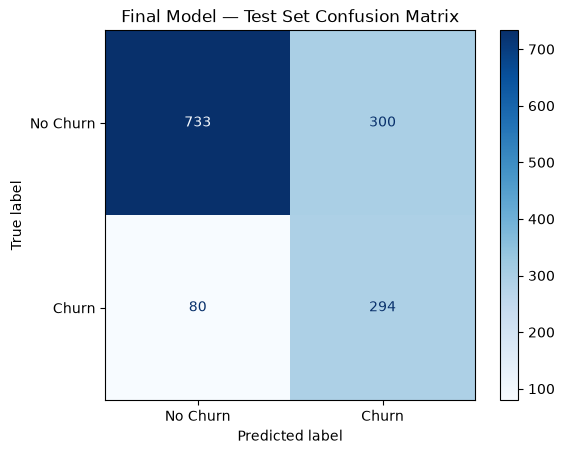

In [150]:
final_model = grid_results["LogReg_L1"].best_estimator_

# GridSearchCV already refitted the selected model on X_train
y_prob_test = final_model.predict_proba(X_test)[:, 1]
y_pred_test = (y_prob_test >= 0.5).astype(int)

print(classification_report(y_test, y_pred_test))

print("Test ROC-AUC:", round(roc_auc_score(y_test, y_prob_test), 4))
print("Test Average Precision:", round(average_precision_score(y_test, y_prob_test), 4))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_test,
    display_labels=["No Churn", "Churn"],
    cmap="Blues"
)

plt.title("Final Model — Test Set Confusion Matrix")
plt.show()

The selected Logistic Regression (L1) model achieved a test ROC-AUC of 0.834, churn recall of 78.6%, and precision of 49.5%.

The model correctly identified 294 out of 374 actual churners, while missing 80 customers. This supports the business objective of identifying customers at risk of leaving and providing opportunities for retention efforts.

However, the model also incorrectly flagged 300 non-churning customers, highlighting the potential cost of unnecessary retention interventions.

Overall, the test results were close to the cross-validation results, suggesting reasonable generalisation performance. While the model demonstrates useful predictive capability, its practical effectiveness would depend on retention costs and how successfully the company can prevent identified customers from leaving.

# 10. Baseline vs. Final Model Comparison

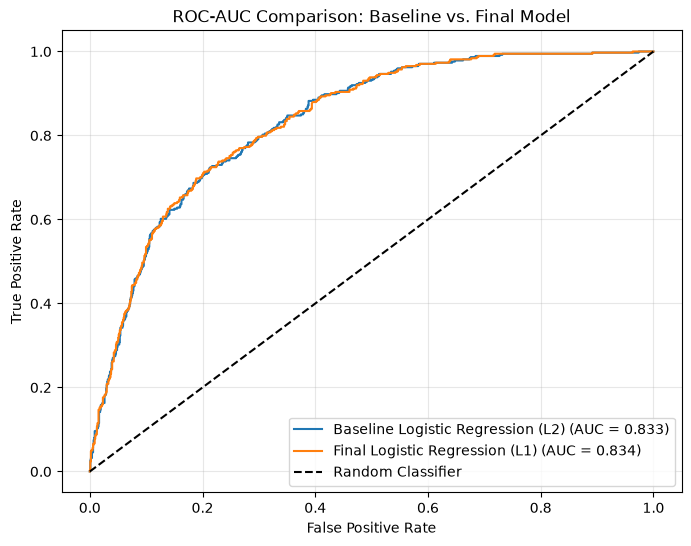

In [151]:
# Recreate the original baseline
baseline_model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

baseline_model.fit(X_train, y_train)

# Retrieve final tuned model
final_model = grid_results["LogReg_L1"].best_estimator_

# Predicted probabilities
baseline_prob = baseline_model.predict_proba(X_test)[:, 1]
final_prob = final_model.predict_proba(X_test)[:, 1]

# Calculate ROC curves and AUC
plt.figure(figsize=(8, 6))

for name, y_prob in [
    ("Baseline Logistic Regression (L2)", baseline_prob),
    ("Final Logistic Regression (L1)", final_prob)
]:
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_score = roc_auc_score(y_test, y_prob)

    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_score:.3f})")

# Random classifier
plt.plot([0, 1], [0, 1], "k--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-AUC Comparison: Baseline vs. Final Model")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.show()

The ROC-AUC comparison shows that both models achieved nearly identical performance, with the final model improving slightly from 0.833 to 0.834.

This suggests that the final model did not substantially improve its overall ability to distinguish churners from non-churners.

However, the main improvement was in churn recall, which increased from 57.5% to 78.6%, reducing the number of missed churners from 159 to 80.

Although this resulted in more false positives, the final model better aligns with the business objective of identifying customers at risk of leaving.

Overall, the final model's main advantage is its higher churn detection rate at the selected threshold, rather than a meaningful improvement in ROC-AUC.

# 11. Business Insights and Recommendations

The Logistic Regression model identified several customer characteristics associated with churn risk, providing useful insights for customer retention strategies.

**Key Findings**
- Contract Type: Customers on month-to-month contracts are associated with higher churn risk, while longer-term contracts are associated with lower risk.
- Customer Tenure: Customers with shorter subscription histories are more likely to be classified as churners, suggesting that newer customers may require additional attention.
- Monthly Charges: Higher monthly charges are associated with increased churn risk, potentially indicating price sensitivity.
- Additional Services: Customers with online security and technical support services show lower predicted churn risk.

**Business Recommendations**

Based on these findings, the telecommunications company could:

- Prioritise high-risk customers: Use the model's predictions to identify customers who may benefit from targeted retention efforts.
- Improve early customer engagement: Investigate ways to support newer customers, particularly those on month-to-month contracts.
- Review pricing and incentives: Consider personalised retention offers for customers with higher monthly charges.
- Evaluate additional services: Investigate whether security and technical support services contribute to customer satisfaction and retention.

**Practical Considerations**
The final model identifies approximately 79% of actual churners but has a precision of approximately 50%. Therefore, retention campaigns should consider the potential costs of incorrectly targeting customers who would otherwise stay.

Furthermore, the identified features represent predictive associations rather than proven causes of churn. The effectiveness of proposed retention strategies would need to be evaluated through further analysis or controlled experiments.

# 12. Limitations

Although the final Logistic Regression model achieved promising churn recall, several limitations should be considered:

- False Positives: With a precision of 49.5%, the model incorrectly identifies many non-churning customers as potential churners, which could lead to unnecessary retention costs.
- Lack of Business Cost Data: Without information on customer lifetime value and retention expenses, it is difficult to determine the most cost-effective classification threshold.
- Probability Calibration: Since the model uses balanced class weights, its predicted probabilities may not accurately reflect actual churn probabilities.
- Correlation vs. Causation: The identified features are associated with churn but do not necessarily cause customers to leave.
- Evaluation Limitations: The test set was examined during initial baseline experiments, meaning the final evaluation was not entirely independent of the development process.

Future improvements could include probability calibration, cost-based threshold optimisation, and evaluation on new, unseen customer data.